# OCEAVERA — Notebook 08: Feature Selection, Engineering and Preprocessing

**Project:** OCEAVERA · IT3091 · Group 2026-AI-45  
**Branch:** pipeline/exploratory-data-analysis  
**Review date:** 16 October 2026  
**Architecture:** B — one shared, species-conditioned model

**Data lineage:** presence_background_candidates.parquet → preliminary eligibility → one positive per taxon/cell/period with its paired background → spatial blocks → deterministic feature engineering → three provisional feature sets → unfitted preprocessing templates.

**Labels:** 1 = recorded taxon occurrence; 0 = sampled background, not confirmed absence. Environmental values for 2020–2026 use the SSP245 2020 projected assumption. The broad background domain, spatial dependence and geographic/depth contrast remain unresolved. No classifiers are trained and no preprocessing estimator is fitted on the real dataset.

### Notebook visualization policy

Every figure is generated directly by Python plotting code in an executed Code cell from current Script 12 outputs. The notebook does not load pre-rendered charts or write dataset files. All visualizations are descriptive diagnostics, not predictions.

## Contributors

| Registration Number | Member Name | GitHub Account |
|---|---|---|
| IT24103038 | Adithya Gunawardana | AdithyaGunawardana |
| IT24100184 | Ushan Srinuka | Ushan-Srinuka |

## Purpose and scope

This notebook documents the feature preparation stage after the descriptive EDA. It reads the accepted frozen presence–background GeoParquet and Script 12's derived reports, candidate table and unfitted templates. The script is executed separately before the notebook. Notebook cells do not regenerate data, fit estimators or train classifiers.

The stage provides provisional population reduction, global spatial partitions, training-only coverage screening, three transparent environmental feature hypotheses and reusable preprocessing configurations. It does not approve species, the background domain, an ecological target, final features or model methods.

## Data and provenance

The read-only input is data/interim/pseudo_absence/presence_background_candidates.parquet (4,706 rows × 527 columns, 382 Bio-ORACLE features; SHA-256 234177bf3641856cdd10b425f2da957a27210f876d31092ba715a53cee7a429f). Its labels are observed presence (1) and sampled background (0); the latter is not a verified absence.

The accepted integration audit records period-specific quarantines. Script 12 checks these remain null, screens all 382 source variables using training rows only, and retains source columns unchanged in the frozen input. Occurrences in 2020–2026 use SSP245 2020 assumptions rather than annual observations. The broad-ocean background and environmental contrasts remain evaluation risks.

## Branch result and workflow

| Stage | Canonical artefact | Result |
|---|---|---|
| Population and spatial split | src/data_preparation/12_feature_engineering_and_preprocessing.py | New deduplicated modelling view, paired labels, 0.5° block partitions |
| Feature screening and engineering | data/interim/model_preparation/feature_screen_train_only.csv | Training-only screening for all 382 environmental variables; source quarantines checked |
| Candidate predictors | data/interim/model_preparation/feature_set_manifest.json | Core, core-plus-engineered and domain-expanded hypotheses |
| Taxon support | data/interim/model_preparation/taxon_spatial_support.csv | Positive cells and spatial support by partition |
| Preprocessing | Six unfitted_*_preprocessor.joblib files | Reusable templates; no fitted statistics |
| Evidence | docs/records/2026-10-16-feature-preprocessing-report.md and .json | Counts, hashes, split and limitations |

This notebook reads and visualizes those saved results. Its Code cells do not write derived dataset files.

## Load Script 12 results (read-only)

Run python src/data_preparation/12_feature_engineering_and_preprocessing.py before opening this notebook. The cell below verifies the frozen source hash and loads the completed reports and plotting libraries without re-running the script.

In [1]:
from pathlib import Path
import hashlib
import importlib.metadata as metadata
import json
import pandas as pd
import geopandas as gpd
from IPython.display import display, Markdown

MARKER = Path('src/data_preparation/12_feature_engineering_and_preprocessing.py')
ROOT = next((path for path in (Path.cwd(), *Path.cwd().parents) if (path / MARKER).is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Could not locate the OCEAVERA repository root')
SOURCE = ROOT / 'data/interim/pseudo_absence/presence_background_candidates.parquet'
REPORT = ROOT / 'docs/records/2026-10-16-feature-preprocessing-summary.json'
with SOURCE.open('rb') as source_file:
    source_hash = hashlib.file_digest(source_file, 'sha256').hexdigest()
summary = json.loads(REPORT.read_text(encoding='utf-8'))
assert source_hash == summary['input']['sha256_before_after'][0]
assert summary['input']['sha256_before_after'][0] == summary['input']['sha256_before_after'][1]
print('Frozen source SHA-256:', source_hash)
print('Derived candidate:', summary['output'])
print('Python:', __import__('sys').version.split()[0])
for package in ['numpy', 'pandas', 'geopandas', 'pyarrow', 'scikit-learn', 'matplotlib', 'seaborn']:
    print(f'{package}: {metadata.version(package)}')
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110

Frozen source SHA-256: 234177bf3641856cdd10b425f2da957a27210f876d31092ba715a53cee7a429f
Derived candidate: {'path': 'data/interim/model_preparation/ml_candidates.parquet', 'rows': 2308, 'columns': 26, 'bytes': 250215, 'sha256': 'a7fceef9b925eda28bfc6ca9d3e00ddbe9a554aca2617ee31b1dfe0e3c47c148', 'crs': '{"$schema": "https://proj.org/schemas/v0.7/projjson.schema.json", "type": "GeographicCRS", "name": "WGS 84", "datum_ensemble": {"name": "World Geodetic System 1984 ensemble", "members": [{"name": "World Geodetic System 1984 (Transit)"}, {"name": "World Geodetic System 1984 (G730)"}, {"name": "World Geodetic System 1984 (G873)"}, {"name": "World Geodetic System 1984 (G1150)"}, {"name": "World Geodetic System 1984 (G1674)"}, {"name": "World Geodetic System 1984 (G1762)"}, {"name": "World Geodetic System 1984 (G2139)"}, {"name": "World Geodetic System 1984 (G2296)"}], "ellipsoid": {"name": "WGS 84", "semi_major_axis": 6378137, "inverse_flattening": 298.257223563}, "accuracy": "2.0", "id": {

## Phase 1 — Define the modelling population and handle repeats

The frozen full source retains every one of the 4,706 candidate rows. In a **new modelling view only**, pairs failing preliminary species-level eligibility are excluded; repeated positive observations from the same `(target_taxon_key, grid_cell_id, analysis_period)` are represented once, with their existing paired background. This is evidence control, not a claim of new sampling or biological independence.

,result
source_rows,4706
eligible_input_rows,3458
excluded_rows_before_eligibility,1248
excluded_positive_rows_before_eligibility,624
excluded_background_rows_before_eligibility,624
excluded_distinct_taxa_by_label,"{'0': 280, '1': 280}"
eligible_distinct_taxa_by_label,"{'0': 441, '1': 441}"
ineligible_reason_counts_by_label_nonexclusive,"{'0': {'unverified_species_rank': 344, 'source..."
eligible_source_presences,1729
eligible_paired_backgrounds,1729


The source 4,706-row GeoParquet was not changed.


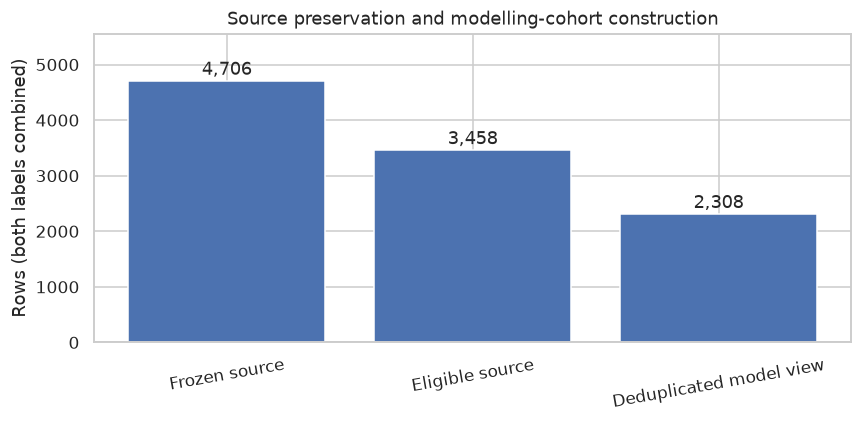

In [2]:
display(pd.DataFrame([summary['population']]).T.rename(columns={0:'result'}))
print('The source 4,706-row GeoParquet was not changed.')
# Live plot: how the frozen candidate population becomes the derived cohort.
pop = summary['population']
steps = ['Frozen source', 'Eligible source', 'Deduplicated model view']
amounts = [int(pop['source_rows']), int(pop['eligible_input_rows']),
           int(pop['balanced_candidate_rows'])]
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(steps, amounts)
for bar, number in zip(bars, amounts):
    ax.annotate(f'{number:,}', (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                xytext=(0, 4), textcoords='offset points', ha='center')
ax.set_ylabel('Rows (both labels combined)')
ax.set_title('Source preservation and modelling-cohort construction')
ax.set_ylim(0, max(amounts) * 1.18)
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()


## Phase 2 — Spatially grouped train/validation/test partitions

Spatial blocks are assigned from **Bio-ORACLE raster-cell centres**, consistently across taxa and periods. No raster cell or block appears in more than one split. The seed is fixed; spatial independence is still approximate due to finite block width. Rare taxa may be missing in training or held-out partitions and are reported rather than silently interpreted.

Derived GeoParquet: (2308, 26) CRS: {"$schema": "https://proj.org/schemas/v0.7/projjson.schema.json", "type": "GeographicCRS", "name": "WGS 84", "datum_ensemble": {"name": "World Geodetic System 1984 ensemble", "members": [{"name": "World Geodetic System 1984 (Transit)"}, {"name": "World Geodetic System 1984 (G730)"}, {"name": "World Geodetic System 1984 (G873)"}, {"name": "World Geodetic System 1984 (G1150)"}, {"name": "World Geodetic System 1984 (G1674)"}, {"name": "World Geodetic System 1984 (G1762)"}, {"name": "World Geodetic System 1984 (G2139)"}, {"name": "World Geodetic System 1984 (G2296)"}], "ellipsoid": {"name": "WGS 84", "semi_major_axis": 6378137, "inverse_flattening": 298.257223563}, "accuracy": "2.0", "id": {"authority": "EPSG", "code": 6326}}, "coordinate_system": {"subtype": "ellipsoidal", "axis": [{"name": "Geodetic latitude", "abbreviation": "Lat", "direction": "north", "unit": "degree"}, {"name": "Geodetic longitude", "abbreviation": "Lon", "direction": "east", "unit

presence_background_label,0,1,All
split,,,
test,173,172,345
train,801,803,1604
validation,180,179,359
All,1154,1154,2308


Spatial overlap counts: 0 0


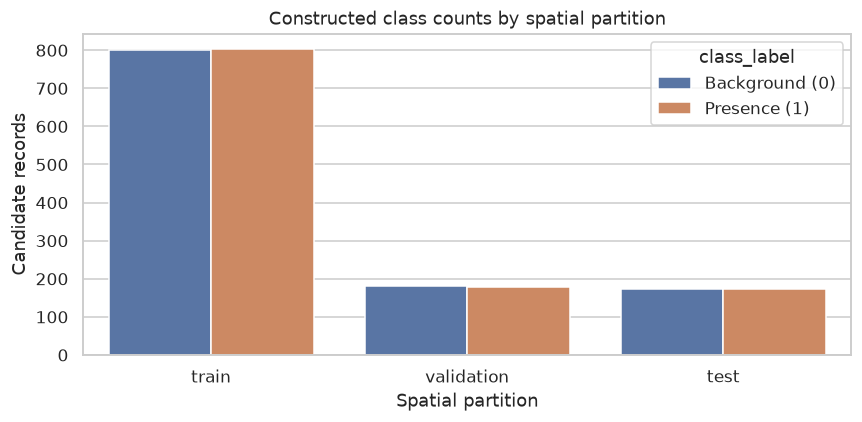

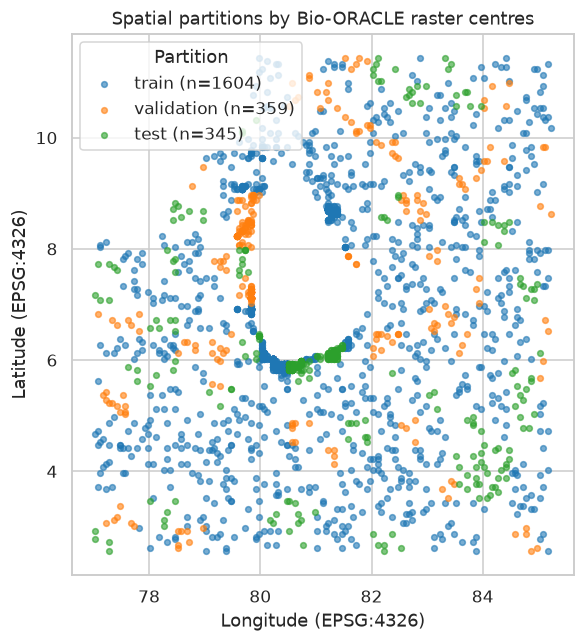

In [3]:
prepared = gpd.read_parquet(ROOT / summary['output']['path'])
print('Derived GeoParquet:', prepared.shape, 'CRS:', prepared.crs)
display(pd.crosstab(prepared['split'], prepared['presence_background_label'], margins=True))
print('Spatial overlap counts:', summary['spatial_split']['cross_split_cell_overlap'],
      summary['spatial_split']['cross_split_spatial_block_overlap'])
# Live plot 1: target balance across spatially isolated partitions.
plot_counts = (prepared.groupby(['split', 'presence_background_label']).size()
               .rename('records').reset_index())
plot_counts['class_label'] = plot_counts['presence_background_label'].map(
    {0: 'Background (0)', 1: 'Presence (1)'})
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=plot_counts, x='split', y='records', hue='class_label',
            order=['train', 'validation', 'test'], errorbar=None, ax=ax)
ax.set_title('Constructed class counts by spatial partition')
ax.set_xlabel('Spatial partition')
ax.set_ylabel('Candidate records')
plt.tight_layout()
plt.show()

# Live plot 2: actual raster-centre locations coloured by assigned split.
fig, ax = plt.subplots(figsize=(8, 6))
colors = {'train': 'tab:blue', 'validation': 'tab:orange', 'test': 'tab:green'}
for partition in ['train', 'validation', 'test']:
    piece = prepared.loc[prepared['split'].eq(partition)]
    ax.scatter(piece['raster_cell_center_longitude'], piece['raster_cell_center_latitude'],
               s=14, alpha=.60, label=f'{partition} (n={len(piece)})',
               c=colors[partition], rasterized=True)
ax.set_title('Spatial partitions by Bio-ORACLE raster centres')
ax.set_xlabel('Longitude (EPSG:4326)')
ax.set_ylabel('Latitude (EPSG:4326)')
ax.legend(title='Partition')
ax.set_aspect('equal', adjustable='box')
plt.tight_layout()
plt.show()


## Phase 3 — Initial feature screening

Source identifiers, acquisition provenance, `sample_type`, location/quality flags and sample lineage are never considered habitat predictors. Train-only available nutrient features are screened by coverage and constancy. Complete source definitions, scientific quarantine provenance and non-selected fields remain in the frozen dataset.

,feature,train_present_count,train_missing_count,train_present_fraction,train_distinct_finite,all_null_in_training,constant_in_training,source_quarantined_periods,role,in_any_proposed_feature_set,admitted_to_domain_expanded_set,screening_decision,screen_scope
36,bio_oracle__clt_sd__depthsurf,0,1604,0.000000,0,True,True,ssp245_2020,source Bio-ORACLE,False,False,source quarantine; excluded from optional cand...,train partition only
350,bio_oracle__tas_range__depthsurf,0,1604,0.000000,0,True,True,"baseline_2000, baseline_2010, ssp245_2020",source Bio-ORACLE,False,False,source quarantine; excluded from optional cand...,train partition only
37,bio_oracle__coastline__benthic,562,1042,0.350374,1,False,True,NaN,source Bio-ORACLE,False,False,not in the prespecified core or optional candi...,train partition only
25,bio_oracle__chl_range__depthmax,595,1009,0.370948,238,False,False,NaN,source Bio-ORACLE,False,False,not in the prespecified core or optional candi...,train partition only
27,bio_oracle__chl_range__depthmin,595,1009,0.370948,235,False,False,NaN,source Bio-ORACLE,False,False,not in the prespecified core or optional candi...,train partition only
23,bio_oracle__chl_min__depthmin,595,1009,0.370948,232,False,False,NaN,source Bio-ORACLE,False,False,not in the prespecified core or optional candi...,train partition only
22,bio_oracle__chl_min__depthmean,595,1009,0.370948,230,False,False,NaN,source Bio-ORACLE,False,False,not in the prespecified core or optional candi...,train partition only
21,bio_oracle__chl_min__depthmax,595,1009,0.370948,236,False,False,NaN,source Bio-ORACLE,False,False,not in the prespecified core or optional candi...,train partition only
26,bio_oracle__chl_range__depthmean,595,1009,0.370948,234,False,False,NaN,source Bio-ORACLE,False,False,not in the prespecified core or optional candi...,train partition only
71,bio_oracle__kdpar_mean_range__depthsurf,595,1009,0.370948,403,False,False,NaN,source Bio-ORACLE,False,False,not in the prespecified core or optional candi...,train partition only


Optional candidates: ['bio_oracle__no3_mean__depthsurf', 'bio_oracle__po4_mean__depthsurf', 'bio_oracle__slope__benthic', 'bio_oracle__mlotst_mean__depthsurf']
Optional rejected: {'bio_oracle__silicate_mean__depthsurf': 'source column unavailable', 'bio_oracle__sio4_mean__depthsurf': 'source column unavailable', 'bio_oracle__pp_mean__depthsurf': 'source column unavailable'}


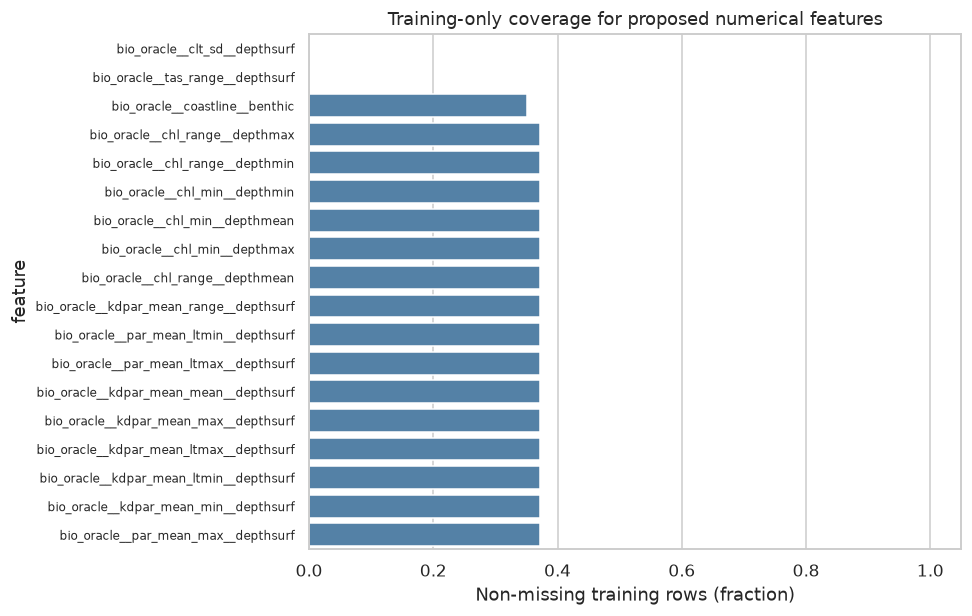

In [4]:
screen = pd.read_csv(ROOT / 'data/interim/model_preparation/feature_screen_train_only.csv')
display(screen.sort_values('train_present_fraction').head(15))
print('Optional candidates:', summary['feature_screening']['optional_columns_admitted_from_training_only'])
print('Optional rejected:', summary['feature_screening']['optional_columns_rejected'])
# Live plot: feature availability is measured on TRAIN ONLY.
screen_plot = screen.sort_values('train_present_fraction', ascending=True).head(18).copy()
fig, ax = plt.subplots(figsize=(9, max(4, len(screen_plot) * .32)))
sns.barplot(data=screen_plot, x='train_present_fraction', y='feature',
            color='steelblue', errorbar=None, ax=ax)
ax.set_xlim(0, 1.05)
ax.set_xlabel('Non-missing training rows (fraction)')
ax.set_title('Training-only coverage for proposed numerical features')
ax.tick_params(axis='y', labelsize=8)
plt.tight_layout()
plt.show()


## Phase 4 — Feature engineering

Create positive water depth from negative bathymetry, its `log1p` representation, and a temperature × salinity interaction. These deterministic formulas use no fitted statistics and preserve nulls. The interaction is a testable candidate rather than a physical oceanographic identity.

,engineered_feature,formula_and_limitation
0,eng_water_depth_m,"max(0, -bathymetry_mean); do not replace null"
1,eng_log1p_water_depth,log1p(eng_water_depth_m)
2,eng_temperature_salinity_interaction,temperature_celsius * salinity_psu; explorator...


,rows,missing,finite_nonmissing,zero_values,minimum,maximum
bio_oracle__thetao_mean__depthsurf,2308.0,0.0,2308.0,0.0,27.555835,29.602480
bio_oracle__so_mean__depthsurf,2308.0,0.0,2308.0,0.0,32.532137,34.811646
bio_oracle__o2_mean__depthsurf,2308.0,0.0,2308.0,0.0,198.211291,204.135327
bio_oracle__chl_mean__depthsurf,2308.0,0.0,2308.0,0.0,0.110450,0.987700
bio_oracle__ph_mean__depthsurf,2308.0,0.0,2308.0,0.0,8.008260,8.065125
bio_oracle__bathymetry_mean__benthic,2308.0,0.0,2308.0,30.0,-4410.388672,0.000000
eng_water_depth_m,2308.0,0.0,2308.0,30.0,-0.000000,4410.388672
eng_log1p_water_depth,2308.0,0.0,2308.0,30.0,-0.000000,8.391945
eng_temperature_salinity_interaction,2308.0,0.0,2308.0,0.0,934.856180,1019.832252
bio_oracle__no3_mean__depthsurf,2308.0,0.0,2308.0,0.0,0.003333,1.115424


,bio_oracle__bathymetry_mean__benthic,eng_water_depth_m,eng_log1p_water_depth,eng_temperature_salinity_interaction
0,-16.555555,16.555555,2.865370,967.789483
1,-7.000000,7.000000,2.079442,982.860189
2,-1020.250000,1020.250000,6.928783,968.278886
3,-12.805555,12.805555,2.625071,961.352367
4,-38.583332,38.583332,3.678408,960.551350
5,-22.000000,22.000000,3.135494,989.904581
6,-16.555555,16.555555,2.865370,967.789483
7,-16.555555,16.555555,2.865370,967.789483


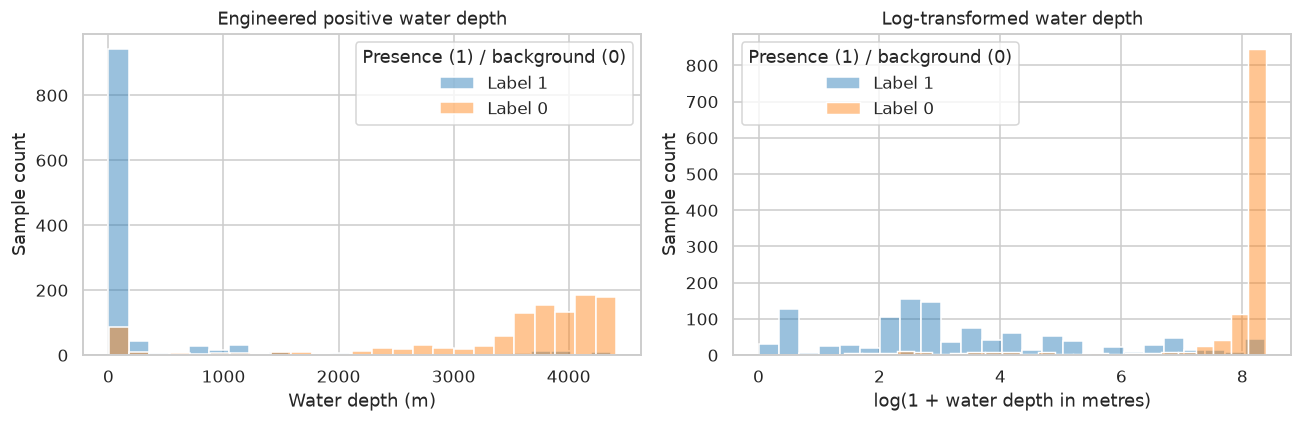

In [5]:
eng = summary['engineering']
display(pd.DataFrame({'engineered_feature':list(eng),'formula_and_limitation':list(eng.values())}))
display(pd.DataFrame(summary['candidate_feature_quality']).T)
view = ['bio_oracle__bathymetry_mean__benthic',
        'eng_water_depth_m','eng_log1p_water_depth','eng_temperature_salinity_interaction']
display(prepared[view].head(8))
# Live plot: depth engineering, retaining legitimate zero-depth locations.
# This is descriptive visualization; no global scaler or imputer is fitted.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for label, color in [(1, 'tab:blue'), (0, 'tab:orange')]:
    subset = prepared.loc[prepared['presence_background_label'].eq(label)]
    d = pd.to_numeric(subset['eng_water_depth_m'], errors='coerce').dropna()
    dlog = pd.to_numeric(subset['eng_log1p_water_depth'], errors='coerce').dropna()
    sns.histplot(x=d, bins=25, alpha=.45, label=f'Label {label}', color=color, ax=axes[0])
    sns.histplot(x=dlog, bins=25, alpha=.45, label=f'Label {label}', color=color, ax=axes[1])
axes[0].set_title('Engineered positive water depth')
axes[0].set_xlabel('Water depth (m)')
axes[1].set_title('Log-transformed water depth')
axes[1].set_xlabel('log(1 + water depth in metres)')
for ax in axes:
    ax.set_ylabel('Sample count')
    ax.legend(title='Presence (1) / background (0)')
fig.tight_layout()
plt.show()


## Phase 5 — Specify three compareable feature sets

1. Six original core predictors.
2. Core-and-engineered, with log depth replacing raw bathymetry.
3. Domain-expanded, adding validated nutrient/physical candidates only when source exists and training coverage is adequate.

**Species identity** is one-hot encoded separately in all three. These are proposals, not model evaluation outcomes. Do not perform supervised feature selection on all rows before a split.

,set,numeric_features,features
0,core_six,6,"bio_oracle__thetao_mean__depthsurf, bio_oracle..."
1,core_plus_engineered,9,"bio_oracle__thetao_mean__depthsurf, bio_oracle..."
2,domain_expanded,13,"bio_oracle__thetao_mean__depthsurf, bio_oracle..."


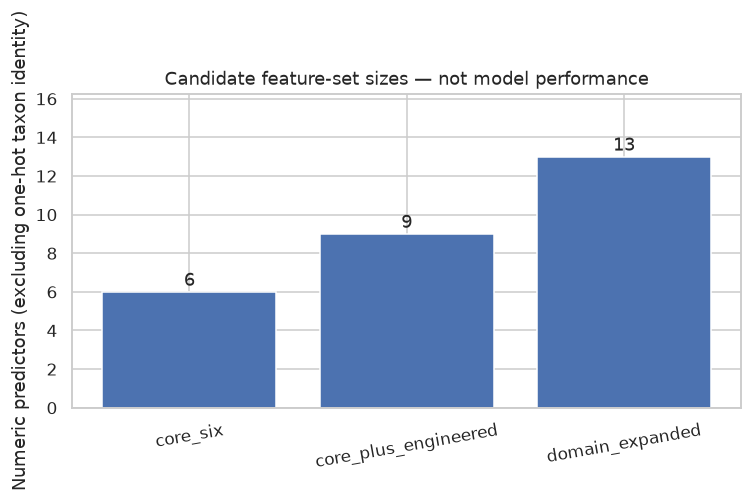

In [6]:
sets = summary['feature_sets']
display(pd.DataFrame([{'set':k,'numeric_features':len(v),'features':', '.join(v)} for k,v in sets.items()]))
# Live plot: dimensionality of the prespecified numerical feature sets.
fig, ax = plt.subplots(figsize=(7, 4))
set_names = list(sets)
set_sizes = [len(sets[name]) for name in set_names]
bars = ax.bar(set_names, set_sizes)
for bar, count in zip(bars, set_sizes):
    ax.annotate(str(count), (bar.get_x() + bar.get_width()/2, bar.get_height()),
                xytext=(0, 4), textcoords='offset points', ha='center')
ax.set_ylim(0, max(set_sizes) * 1.25)
ax.set_ylabel('Numeric predictors (excluding one-hot taxon identity)')
ax.set_title('Candidate feature-set sizes — not model performance')
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()


## Phase 6 — Unfitted preprocessing pipelines

Six `joblib` templates provide a tree-friendly variant (median imputation, one-hot species) and scaled variant (median imputation, standard scaling, one-hot species). **None is fitted** at publication. During future model comparison, fit each pipeline only inside a training fold and apply the learned transform to that fold's validation/test data. Zero-variance/source-quarantined features are not automatically imputed from an entire evaluation population.

,configuration,unfitted,path
0,core_six_tree,True,data/interim/model_preparation/unfitted_core_s...
1,core_six_scaled,True,data/interim/model_preparation/unfitted_core_s...
2,core_plus_engineered_tree,True,data/interim/model_preparation/unfitted_core_p...
3,core_plus_engineered_scaled,True,data/interim/model_preparation/unfitted_core_p...
4,domain_expanded_tree,True,data/interim/model_preparation/unfitted_domain...
5,domain_expanded_scaled,True,data/interim/model_preparation/unfitted_domain...


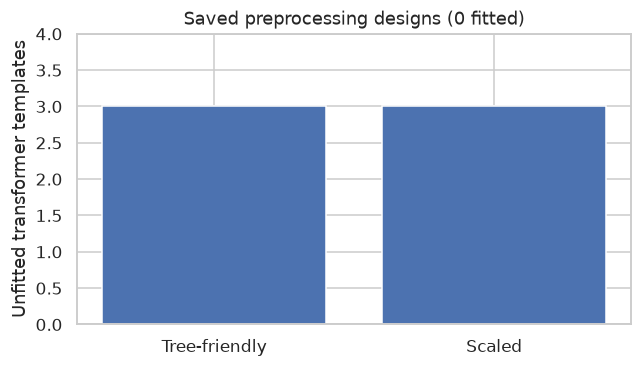

In [7]:
import joblib
rows=[]
for name, meta in summary['unfitted_transformers'].items():
    p = ROOT / meta['path']
    transformer = joblib.load(p)
    assert not hasattr(transformer,'transformers_'), f'Fitted template is forbidden: {name}'
    rows.append({'configuration':name,'unfitted':True,'path':meta['path']})
display(pd.DataFrame(rows))
# Visualize the unfitted template inventory using code-generated data.
# This shows only the preprocessing design; NO pipelines are fitted here.
from collections import Counter
template_counts = Counter('Scaled' if 'scaled' in name else 'Tree-friendly' for name in summary['unfitted_transformers'])
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(list(template_counts), list(template_counts.values()))
ax.set_ylim(0, max(template_counts.values()) + 1)
ax.set_ylabel('Unfitted transformer templates')
ax.set_title('Saved preprocessing designs (0 fitted)')
plt.tight_layout()
plt.show()


## Phase 7 — Validation, model-readiness evidence, and scientific limitations

Model candidates are still *provisional*. A species may have one or many records but only a small number of distinct training/validation/test cells. Broad uniform marine backgrounds create strongly separated bathymetry and coastline distributions. High future classification accuracy must not automatically be reported as calibrated probability or strong habitat ecology. The final model comparison must evaluate spatial groups and training-known taxa.

,target_taxon_key,positive_cell_periods,positive_distinct_cells,positive_distinct_spatial_blocks,train_positive_rows,train_positive_cells,validation_positive_rows,validation_positive_cells,test_positive_rows,test_positive_cells,spatial_evaluation_supported_provisionally
0,AphiaID:137206,71,61,23,54,45,2,2,15,14,True
1,AphiaID:220293,63,59,36,48,44,4,4,11,11,True
2,AphiaID:343936,81,59,13,31,22,12,12,38,25,True
3,AphiaID:137109,35,29,9,22,18,3,3,10,8,True
4,AphiaID:137207,18,17,4,17,16,1,1,0,0,False
5,AphiaID:137135,10,10,6,6,6,2,2,2,2,True
6,AphiaID:159115,10,10,7,4,4,4,4,2,2,True
7,AphiaID:137090,9,9,4,7,7,0,0,2,2,False
8,AphiaID:567792,9,9,3,5,5,0,0,4,4,False
9,AphiaID:105795,9,8,2,9,8,0,0,0,0,False


Taxa with provisional presence support in all splits: 10 of 441
Ineligible or unseen taxon limitations must be considered when interpreting metrics.


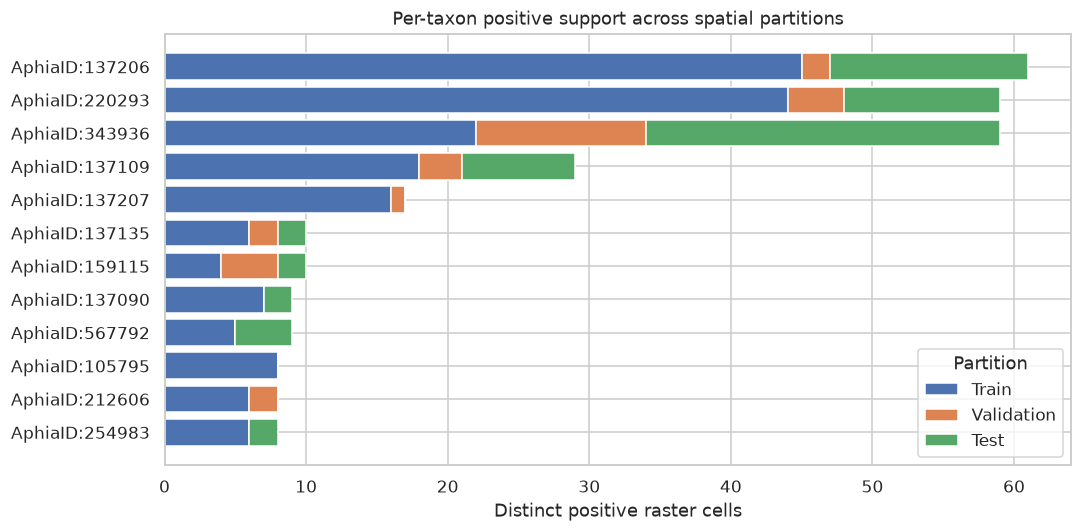

In [8]:
support = pd.read_csv(ROOT / 'data/interim/model_preparation/taxon_spatial_support.csv')
display(support.head(20))
print('Taxa with provisional presence support in all splits:',
      summary['taxon_support']['taxa_with_provisional_support_in_all_splits'],
      'of',summary['taxon_support']['taxa'])
print('Ineligible or unseen taxon limitations must be considered when interpreting metrics.')
# Live plot: leading taxa and their spatial presence support across splits.
needed = ['train_positive_cells', 'validation_positive_cells', 'test_positive_cells']
for col in needed:
    if col not in support:
        raise ValueError(f'Missing support column: {col}')
leaders = support.sort_values('positive_distinct_cells', ascending=False).head(12).copy()
fig, ax = plt.subplots(figsize=(10, 5))
left = np.zeros(len(leaders))
for col, name in [('train_positive_cells', 'Train'),
                  ('validation_positive_cells', 'Validation'),
                  ('test_positive_cells', 'Test')]:
    counts = leaders[col].to_numpy(dtype=float)
    ax.barh(leaders['target_taxon_key'].astype(str), counts, left=left, label=name)
    left += counts
ax.invert_yaxis()
ax.set_xlabel('Distinct positive raster cells')
ax.set_title('Per-taxon positive support across spatial partitions')
ax.legend(title='Partition')
plt.tight_layout()
plt.show()


## Evidence and handoff

Refer to the saved ML preparation JSON, Markdown report, feature log, and taxon spatial support table. The next stage performs training and model comparison using the **train-only** preprocessing templates, a supported taxon cohort, and spatial validation. Do not overwrite the frozen source or falsely treat background scores as ecological occurrence probabilities.

**Figure provenance:** Each preceding figure is built directly by that section's Python cell using current `prepared`, `summary`, `screen`, or `support` data, rather than loaded from a saved image file. No visual result should be treated as model evaluation.


In [9]:
text = (ROOT/'docs/records/2026-10-16-preprocessing-feature-log.md').read_text(encoding='utf-8')
display(Markdown(text))
print('Source unchanged:', summary['input']['sha256_before_after'][0] == summary['input']['sha256_before_after'][1])

# OCEAVERA — Preprocessing and Feature Decision Log

**Status:** provisional technical preparation; shared ecological and feature approval remains pending.

- **Dataset/version:** `data/interim/pseudo_absence/presence_background_candidates.parquet` (4,706 × 527; SHA-256 `234177bf3641856cdd10b425f2da957a27210f876d31092ba715a53cee7a429f`).
- **Evaluation design:** global 0.5° raster-centre spatial blocks with train/validation/test partitions.
- **Derived candidate:** `data/interim/model_preparation/ml_candidates.parquet` (2,308 × 26).

| Date | Field or issue | EDA evidence | Options considered | Chosen treatment | Rationale | Leakage control | Effect on evaluation | Reproduction reference |
|---|---|---|---|---|---|---|---|---|
| 2026-10-16 | Source and target | Use frozen D-056 source; label 1 is observed presence and 0 is sampled background. | EDA source/hash and label dictionary | Preserve full source; use paired eligible records. | Keep the established 1:1 paired candidates | No source rewrite; no absence claim. | Lineage fields are not predictors | Conclusions remain conditional on background sampling. | 2026-10-16-eda-report.md; 2026-10-16-full-population-presence-background-construction.md |
| 2026-10-16 | Repeated records | Retain one positive per taxon/cell/period and its paired background. | 575 repeated positives omitted from this view. | Keep every row or reduce repeated cell-period records. | Use one representative in this derived view. | Avoid treating identical cell-period environmental profiles as independent samples. | Deduplicate before spatial partitioning | Candidate population is smaller than source occurrence population. | 2026-10-16-feature-preprocessing-summary.json |
| 2026-10-16 | Spatial validation | Assign shared 0.5-degree raster-centre blocks to one of three partitions. | No cell/block overlap; split support varies by taxon. | Random rows or geographic blocks. | Use deterministic global block groups, approximately 70/15/15. | Reduce repeated-cell and local spatial leakage. | Do not use held-out environmental values to choose features. | Small and rare taxa may lack independent support. | 2026-10-16-feature-preprocessing-summary.json; taxon_spatial_support.csv |
| 2026-10-16 | Source quarantines and missingness | Screen all 382 environmental fields on training rows; verify period-specific quarantines. | 7 quarantined definitions, 14 affected periods. | Use quarantined values or exclude affected measurements. | Require quarantined source values to remain null; do not propose quarantined optional layers. | Respect unresolved source semantics; preserve all source columns. | Coverage screening is training-only. | Null values require fold-local imputation only if the feature is later approved. | 2026-10-16-integration-final-technical-report.json; feature_screen_train_only.csv |
| 2026-10-16 | Feature engineering | Add positive water depth, log depth and temperature-by-salinity interaction. | Bathymetry has a negative offshore sign; retain null and valid zero-depth values. | Keep raw bathymetry or use derived transforms. | Expose both raw core bathymetry and all three engineered features. | Provide interpretable alternative representations for later comparison. | Operations are deterministic and use no fitted statistics. | No predictive benefit is established. | 2026-10-16-feature-preprocessing-summary.json; test_feature_preprocessing.py |
| 2026-10-16 | Feature configurations | Compare core-six, core-plus-engineered and domain-expanded hypotheses. | Optional layer coverage and variation are measured only on training rows. | Use core predictors, add engineered predictors, or add supported optional layers. | Retain three provisional schemas and species as a categorical condition. | Make alternatives reproducible without finalizing selection. | No test-driven or supervised selection. | Feature list remains subject to group review and spatial support. | feature_set_manifest.json; feature_screen_train_only.csv |
| 2026-10-16 | Preprocessing | Store six unfitted numerical/categorical templates. | Templates reload without fitted attributes. | Fit here or save unfitted reusable pipelines. | Save median imputation, optional scaling and unknown-safe one-hot encoding templates. | Allow later fit within training folds. | No transform/fit call on project data. | Later validation must repeat each fit inside its fold. | unfitted_*_preprocessor.joblib |
| 2026-10-16 | Model training | No classifiers or learned preprocessing are fitted in this stage. | Preparation evidence only. | Train now or hand off to evaluation stage. | Do not train models. | Keep this stage descriptive and reproducible. | Held-out partitions remain unused. | No model performance or final model claim. | 2026-10-16-feature-preprocessing-report.md |


Source unchanged: True
